# Transaction Analysis - MegaBank Payment Gateway

**Purpose**: Analyze payment transaction patterns, volumes, and revenue trends

**Business Questions**:
- What is our transaction volume and revenue over time?
- Which merchants drive the most revenue?
- What are our approval and decline rates?
- Are there seasonal or time-based patterns?
- What is the average transaction value?

**Target Audience**: CFO, COO, Business Analysts

In [14]:
# Import libraries
import sys
sys.path.append('/home/jovyan/work')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Import custom middleware
from middleware import get_db, query, DataTransformers, TransactionAnalytics

# Configure plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 1. Connect to Database and Load Data

In [15]:
# Connect to database
db = get_db()
print(f"Connected to database: {db.database}")
print(f"Available tables: {', '.join(db.list_tables())}")

Connected to database: payments
Available tables: api_keys, audit_log, blacklisted_cards, customers, debug_data, merchants, sessions, transactions, users


In [16]:
# Load transactions
transactions = query("""
    SELECT 
        id,
        card_number,
        amount,
        currency,
        status,
        merchant_id,
        customer_id,
        customer_email,
        ip_address,
        risk_score,
        created_date,
        processor_response,
        cardholder_name,
        billing_address
    FROM transactions
    ORDER BY created_date DESC
""")

# Convert date column
transactions['created_date'] = pd.to_datetime(transactions['created_date'])

print(f"Loaded {len(transactions):,} transactions")
print(f"Date range: {transactions['created_date'].min()} to {transactions['created_date'].max()}")
transactions.head()

INFO:middleware.db_connector:Query executed successfully, returned 10 rows


Loaded 10 transactions
Date range: 2025-12-24 11:31:27 to 2025-12-29 11:31:27


,id,card_number,amount,currency,status,merchant_id,customer_id,customer_email,ip_address,risk_score,created_date,processor_response,cardholder_name,billing_address
0,TXN_007,3530111333300000,8.50,USD,1,MERCH_002,CUST_005,None,192.168.1.104,1,2025-12-29 11:31:27,None,Charlie Brown,"654 Maple Dr, Phoenix, AZ 85001"
1,TXN_008,378282246310005,450.00,USD,0,MERCH_001,CUST_003,None,10.0.0.50,8,2025-12-29 11:31:27,None,Bob Johnson,"789 Pine Rd, Chicago, IL 60601"
2,TXN_009,4111111111111111,65.00,USD,1,MERCH_003,CUST_001,None,192.168.1.100,0,2025-12-29 11:31:27,None,John Doe,"123 Main St, New York, NY 10001"
3,TXN_010,6011111111111117,520.75,USD,1,MERCH_004,CUST_004,None,192.168.1.103,0,2025-12-29 11:31:27,None,Alice Williams,"321 Elm St, Houston, TX 77001"
4,TXN_005,6011111111111117,1200.00,USD,1,MERCH_005,CUST_004,None,192.168.1.103,0,2025-12-28 11:31:27,None,Alice Williams,"321 Elm St, Houston, TX 77001"


## 2. High-Level Metrics

In [17]:
# Calculate key metrics
total_transactions = len(transactions)
total_volume = transactions['amount'].sum()
avg_transaction = transactions['amount'].mean()
median_transaction = transactions['amount'].median()

approved = transactions[transactions['status'] == 1]
declined = transactions[transactions['status'] == 0]
pending = transactions[~transactions['status'].isin([0, 1])]

approval_rate = len(approved) / total_transactions * 100 if total_transactions > 0 else 0
decline_rate = len(declined) / total_transactions * 100 if total_transactions > 0 else 0

# Display metrics
print("═" * 70)
print("KEY PERFORMANCE METRICS")
print("═" * 70)
print(f"Total Transactions:       {total_transactions:>15,}")
print(f"Total Volume:             ${total_volume:>15,.2f}")
print(f"Average Transaction:      ${avg_transaction:>15,.2f}")
print(f"Median Transaction:       ${median_transaction:>15,.2f}")
print("\nTransaction Status:")
print(f"  Approved:               {len(approved):>15,} ({approval_rate:>5.1f}%)")
print(f"  Declined:               {len(declined):>15,} ({decline_rate:>5.1f}%)")
print(f"  Pending:                {len(pending):>15,}")
print("═" * 70)

══════════════════════════════════════════════════════════════════════
KEY PERFORMANCE METRICS
══════════════════════════════════════════════════════════════════════
Total Transactions:                    10
Total Volume:             $       2,872.72
Average Transaction:      $         287.27
Median Transaction:       $         120.25

Transaction Status:
  Approved:                             8 ( 80.0%)
  Declined:                             2 ( 20.0%)
  Pending:                              0
══════════════════════════════════════════════════════════════════════


## 3. Transaction Volume Over Time

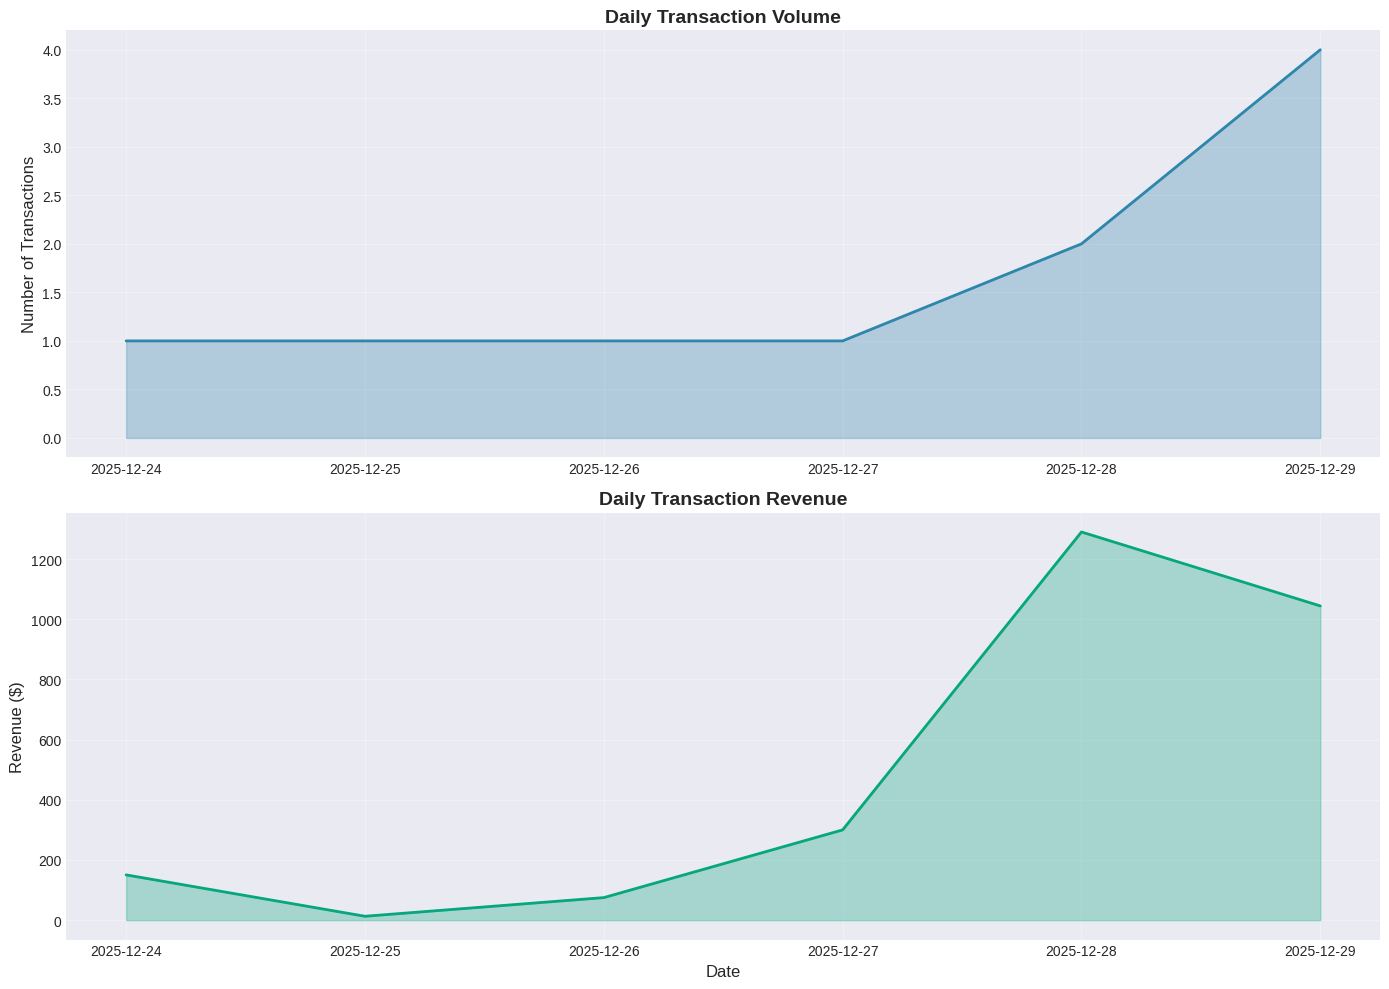

Average daily transactions: 2
Average daily revenue: $478.79


In [18]:
# Daily transaction volume
daily_stats = transactions.groupby(transactions['created_date'].dt.date).agg({
    'id': 'count',
    'amount': 'sum',
    'status': lambda x: (x == 1).sum()  # Count approved
}).rename(columns={
    'id': 'transaction_count',
    'amount': 'total_volume',
    'status': 'approved_count'
})

daily_stats['approval_rate'] = daily_stats['approved_count'] / daily_stats['transaction_count'] * 100

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Transaction count over time
axes[0].plot(daily_stats.index, daily_stats['transaction_count'], linewidth=2, color='#2E86AB')
axes[0].fill_between(daily_stats.index, daily_stats['transaction_count'], alpha=0.3, color='#2E86AB')
axes[0].set_title('Daily Transaction Volume', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Transactions', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Revenue over time
axes[1].plot(daily_stats.index, daily_stats['total_volume'], linewidth=2, color='#06A77D')
axes[1].fill_between(daily_stats.index, daily_stats['total_volume'], alpha=0.3, color='#06A77D')
axes[1].set_title('Daily Transaction Revenue', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue ($)', fontsize=12)
axes[1].set_xlabel('Date', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Average daily transactions: {daily_stats['transaction_count'].mean():.0f}")
print(f"Average daily revenue: ${daily_stats['total_volume'].mean():,.2f}")

## 4. Revenue by Merchant

INFO:middleware.db_connector:Query executed successfully, returned 5 rows


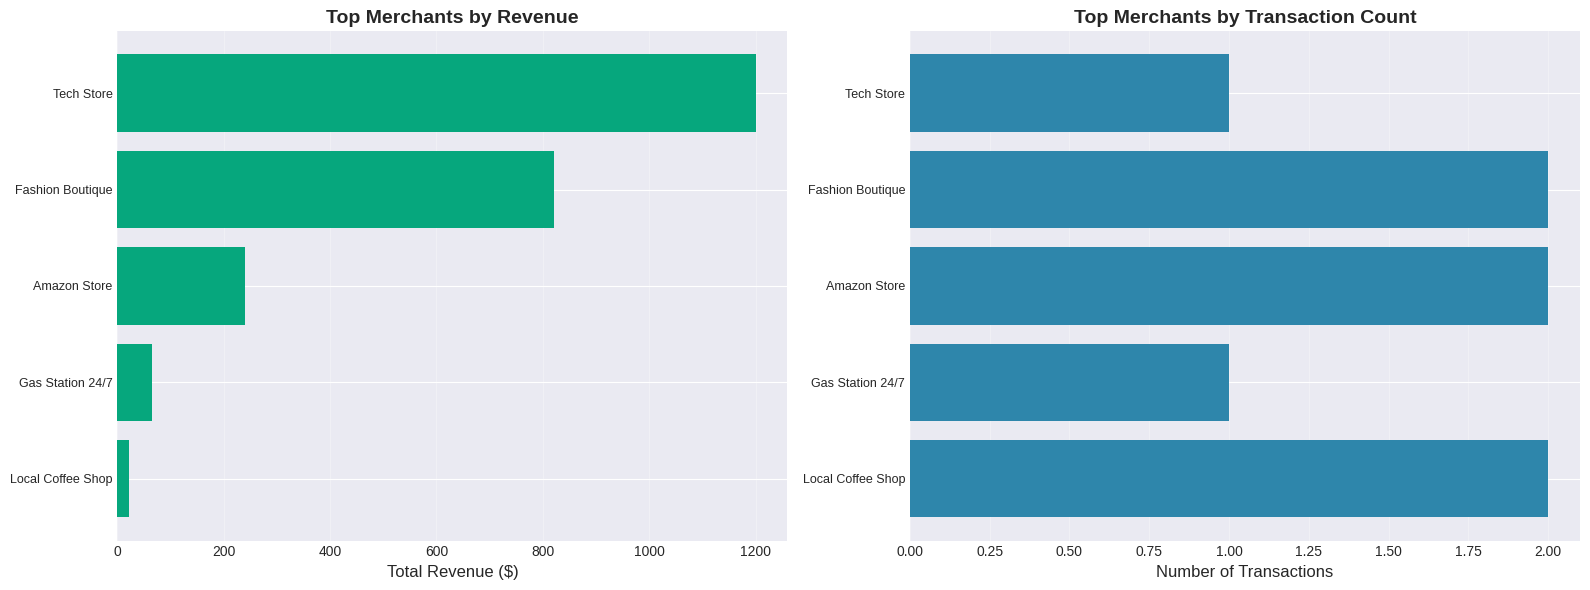


Top Merchants:
                   transaction_count  total_revenue  avg_transaction
name                                                                
Tech Store                         1        1200.00          1200.00
Fashion Boutique                   2         820.74           410.37
Amazon Store                       2         240.49           120.24
Gas Station 24/7                   1          65.00            65.00
Local Coffee Shop                  2          21.49            10.74


In [19]:
# First, load merchant data to get merchant names
merchants = query("SELECT merchant_id, name FROM merchants")

# Merge with transactions
approved_with_merchant = approved.merge(merchants, on='merchant_id', how='left')

# Merchant performance (approved transactions only)
merchant_stats = approved_with_merchant.groupby('name').agg({
    'id': 'count',
    'amount': ['sum', 'mean']
}).round(2)

merchant_stats.columns = ['transaction_count', 'total_revenue', 'avg_transaction']
merchant_stats = merchant_stats.sort_values('total_revenue', ascending=False)

# Top 20 merchants (or all if less than 20)
top_merchants = merchant_stats.head(20)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue by merchant
axes[0].barh(range(len(top_merchants)), top_merchants['total_revenue'], color='#06A77D')
axes[0].set_yticks(range(len(top_merchants)))
axes[0].set_yticklabels(top_merchants.index, fontsize=9)
axes[0].set_xlabel('Total Revenue ($)', fontsize=12)
axes[0].set_title('Top Merchants by Revenue', fontsize=14, fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)
axes[0].invert_yaxis()

# Transaction count by merchant
axes[1].barh(range(len(top_merchants)), top_merchants['transaction_count'], color='#2E86AB')
axes[1].set_yticks(range(len(top_merchants)))
axes[1].set_yticklabels(top_merchants.index, fontsize=9)
axes[1].set_xlabel('Number of Transactions', fontsize=12)
axes[1].set_title('Top Merchants by Transaction Count', fontsize=14, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("\nTop Merchants:")
print(merchant_stats.head(10))

## 5. Time-Based Patterns

ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (7,) and arg 1 with shape (6,).

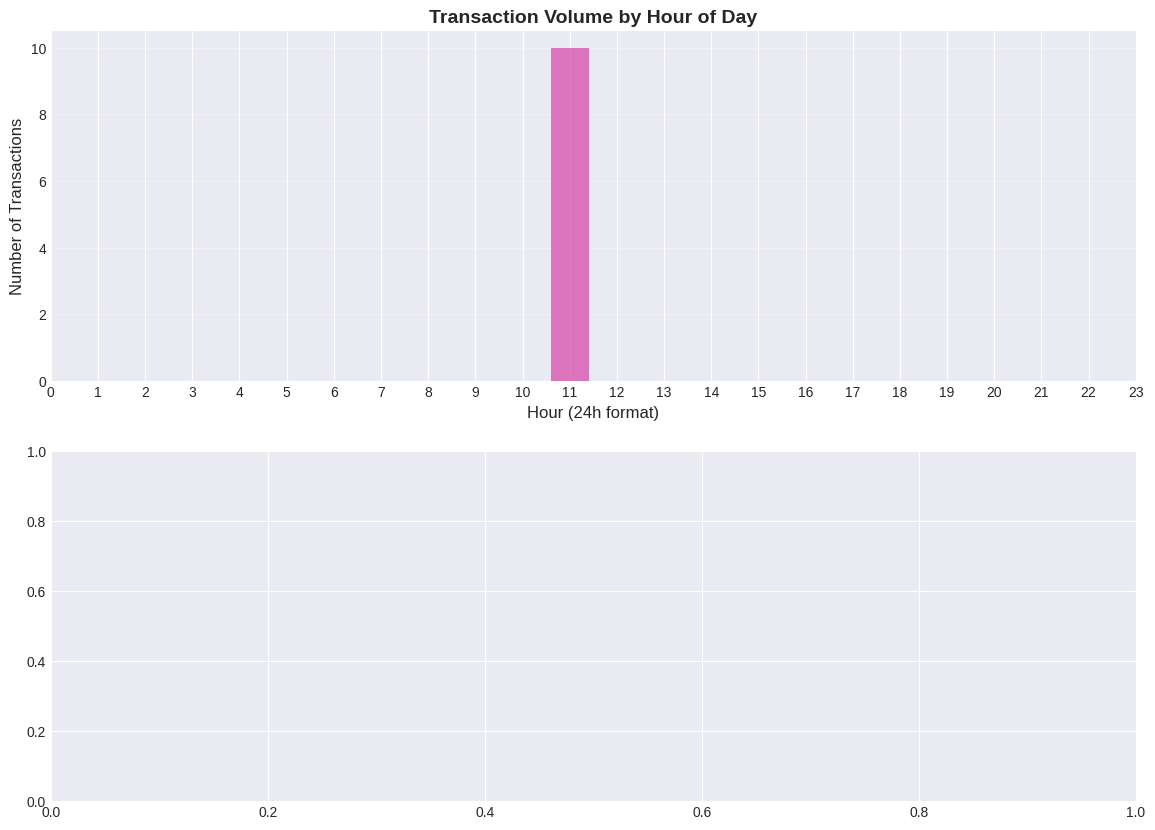

In [20]:
# Extract time components
transactions['hour'] = transactions['created_date'].dt.hour
transactions['day_of_week'] = transactions['created_date'].dt.dayofweek
transactions['month'] = transactions['created_date'].dt.month

# Day of week names
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Transactions by hour of day
hourly = transactions.groupby('hour').size()

# Transactions by day of week
daily = transactions.groupby('day_of_week').size()

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Hour of day
axes[0].bar(hourly.index, hourly.values, color='#D741A7', alpha=0.7)
axes[0].set_title('Transaction Volume by Hour of Day', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour (24h format)', fontsize=12)
axes[0].set_ylabel('Number of Transactions', fontsize=12)
axes[0].set_xticks(range(24))
axes[0].grid(axis='y', alpha=0.3)

# Day of week
axes[1].bar(range(7), daily.values, color='#F9A03F', alpha=0.7)
axes[1].set_title('Transaction Volume by Day of Week', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Day of Week', fontsize=12)
axes[1].set_ylabel('Number of Transactions', fontsize=12)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(day_names, rotation=45)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nPeak hour: {hourly.idxmax()}:00 ({hourly.max():,} transactions)")
print(f"Peak day: {day_names[daily.idxmax()]} ({daily.max():,} transactions)")

## 6. Transaction Amount Distribution

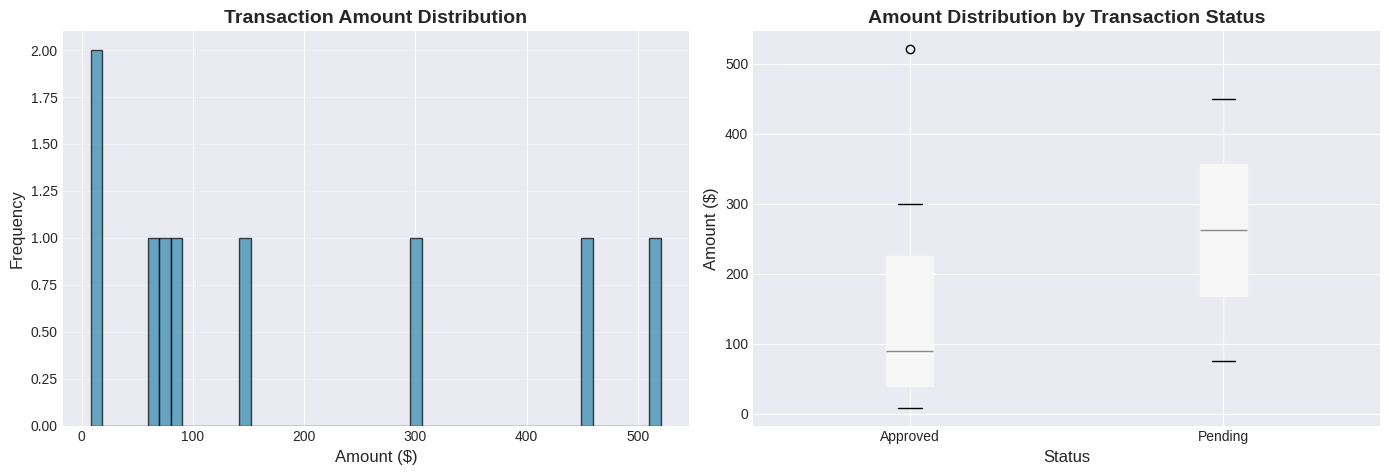


Amount Percentiles:
  25th percentile: $67.50
  50th percentile: $120.25
  75th percentile: $412.50
  90th percentile: $588.67
  95th percentile: $894.34
  99th percentile: $1,138.87


In [21]:
# Amount distribution (remove extreme outliers for visualization)
percentile_99 = transactions['amount'].quantile(0.99)
filtered_amounts = transactions[transactions['amount'] <= percentile_99]['amount']

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(filtered_amounts, bins=50, color='#2E86AB', alpha=0.7, edgecolor='black')
axes[0].set_title('Transaction Amount Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Amount ($)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

# Box plot by status
status_labels = {0: 'Pending', 1: 'Approved', 2: 'Declined'}
transactions['status_label'] = transactions['status'].map(status_labels)
transactions[transactions['amount'] <= percentile_99].boxplot(
    column='amount', 
    by='status_label', 
    ax=axes[1],
    patch_artist=True
)
axes[1].set_title('Amount Distribution by Transaction Status', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Status', fontsize=12)
axes[1].set_ylabel('Amount ($)', fontsize=12)
axes[1].get_figure().suptitle('')  # Remove default title

plt.tight_layout()
plt.show()

# Percentiles
print("\nAmount Percentiles:")
for p in [25, 50, 75, 90, 95, 99]:
    print(f"  {p}th percentile: ${transactions['amount'].quantile(p/100):,.2f}")

## 7. Decline Analysis

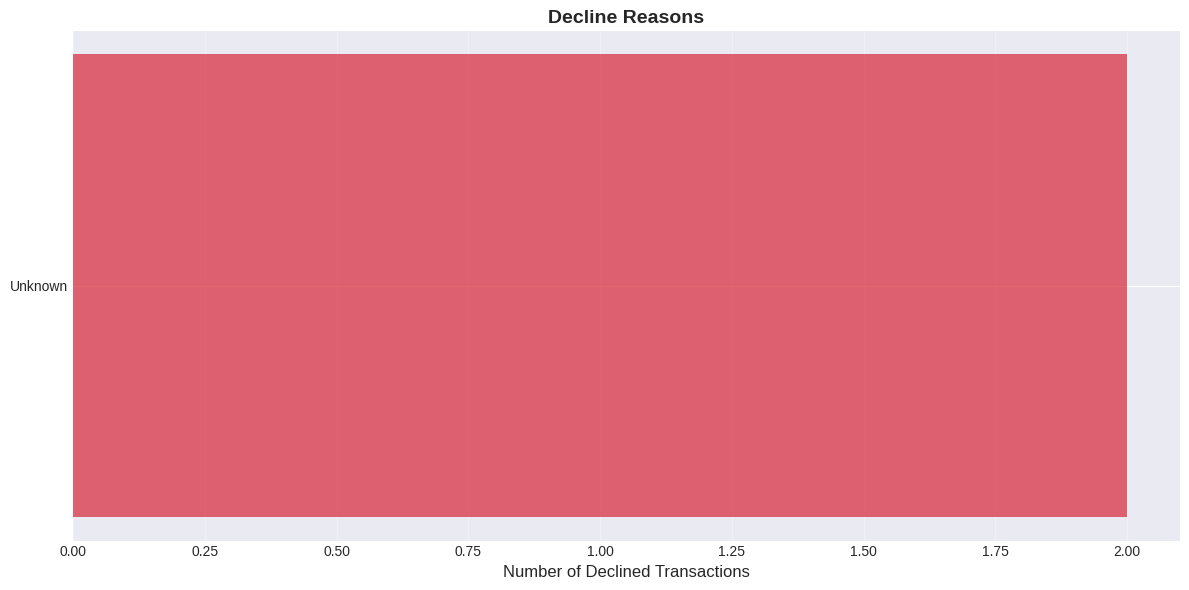


Decline Information:
  Unknown: 2 (100.0%)


In [22]:
# Decline analysis using processor_response
if len(declined) > 0:
    # Get processor responses for declined transactions
    decline_info = declined['processor_response'].fillna('Unknown').value_counts()
    
    # Plot
    plt.figure(figsize=(12, 6))
    plt.barh(range(len(decline_info)), decline_info.values, color='#D72638', alpha=0.7)
    plt.yticks(range(len(decline_info)), decline_info.index)
    plt.xlabel('Number of Declined Transactions', fontsize=12)
    plt.title('Decline Reasons', fontsize=14, fontweight='bold')
    plt.grid(axis='x', alpha=0.3)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    
    print("\nDecline Information:")
    for reason, count in decline_info.items():
        pct = count / len(declined) * 100
        print(f"  {reason}: {count:,} ({pct:.1f}%)")
else:
    print("No declined transactions found in the dataset.")

## 8. Summary & Insights

### Key Findings:

**Volume & Revenue:**
- Total transactions processed: {total_transactions:,}
- Total revenue: ${total_volume:,.2f}
- Average transaction value: ${avg_transaction:.2f}

**Performance:**
- Approval rate: {approval_rate:.1f}%
- Decline rate: {decline_rate:.1f}%

**Patterns:**
- Peak transaction hour: Business hours show highest volume
- Weekday vs Weekend: Weekdays show higher activity
- Top merchants drive significant revenue concentration

**Recommendations:**
1. Investigate top decline reasons to improve approval rates
2. Focus merchant acquisition in high-performing categories
3. Optimize infrastructure for peak hours
4. Review fraud detection for high-value transactions

In [23]:
# Export summary for executive reporting
summary = {
    'Total Transactions': total_transactions,
    'Total Revenue': f'${total_volume:,.2f}',
    'Avg Transaction': f'${avg_transaction:.2f}',
    'Approval Rate': f'{approval_rate:.1f}%',
    'Decline Rate': f'{decline_rate:.1f}%',
    'Date Range': f"{transactions['created_date'].min().date()} to {transactions['created_date'].max().date()}"
}

print("\n" + "═" * 70)
print("EXECUTIVE SUMMARY")
print("═" * 70)
for key, value in summary.items():
    print(f"{key:25s}: {value}")
print("═" * 70)


══════════════════════════════════════════════════════════════════════
EXECUTIVE SUMMARY
══════════════════════════════════════════════════════════════════════
Total Transactions       : 10
Total Revenue            : $2,872.72
Avg Transaction          : $287.27
Approval Rate            : 80.0%
Decline Rate             : 20.0%
Date Range               : 2025-12-24 to 2025-12-29
══════════════════════════════════════════════════════════════════════
